In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

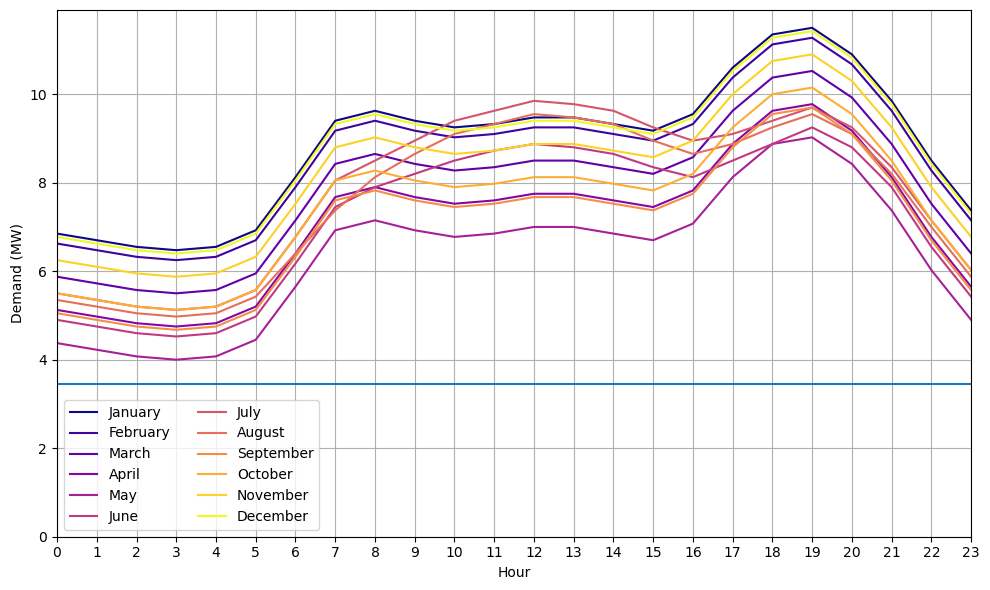

In [ ]:
df_load = pd.read_csv("universal_load_288.csv")
P_base = 4e6 # Base Load = 4 MW
P_peak = 11.5e6 # Peak Load = 11.5 MW
df_load["P_demand"] = ( P_base + df_load["Dimensionless_Load"] * (P_peak - P_base)) # P_demand = P_base + M( month, hour) * (P_peak - P_base)

month_names = ["January", "February", "March", "April","May", "June", "July", "August","September", "October", "November", "December"]

plt.figure(figsize=(10, 6))

cmap = plt.colormaps["plasma"]
for month, group in df_load.groupby("Month"):
    plt.plot( group["Hour"], group["P_demand"]*1e-6, color=cmap((month - 1) / 11), label=month_names[month - 1])

thermal_P_min = P_peak*30/100 #from section 4.2
plt.hlines(thermal_P_min*1e-6 , 0 ,23) # Energy demand is always higher than the minimum 30% of load

plt.xlabel("Hour")
plt.ylabel("Demand (MW)")
plt.xticks(range(24))
plt.xlim((0,23))
plt.ylim(bottom=0)
plt.grid(True)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

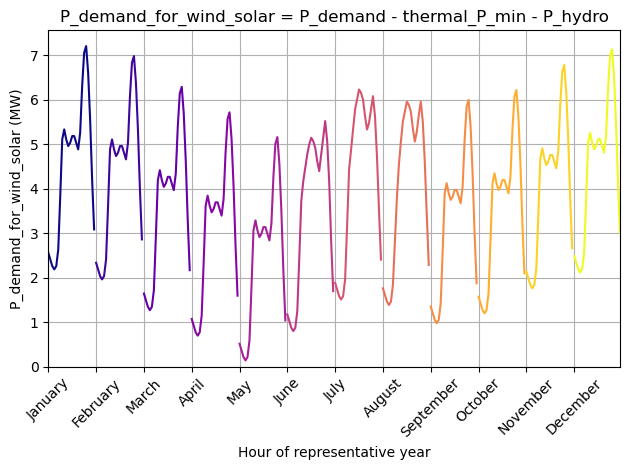

In [15]:
df_hydro = pd.read_csv("hydro_288h.csv")
P_hydro = df_hydro["Power (W)"]
P_demand = df_load["P_demand"]

P_demand_for_wind_solar = P_demand - thermal_P_min - P_hydro
df_load["P_demand_for_wind_solar"] = (df_load["P_demand"] - thermal_P_min - P_hydro)

for month, group in df_load.groupby("Month"):
    plt.plot( (month - 1) * 24 + group["Hour"], group["P_demand_for_wind_solar"]* 1e-6, color=cmap((month - 1) / 11), label=month_names[month - 1], linewidth=1.5    )

plt.xlabel("Hour of representative year")
plt.ylabel("P_demand_for_wind_solar (MW)")
plt.title("P_demand_for_wind_solar = P_demand - thermal_P_min - P_hydro")
# Mark the beginning of each representative day
plt.xticks( np.arange(0, 288, 24), month_names, rotation=45 )

plt.xlim(0, 287)
plt.ylim(bottom=0)
plt.grid(True)
#plt.legend(ncol=2)
plt.tight_layout()
plt.show()

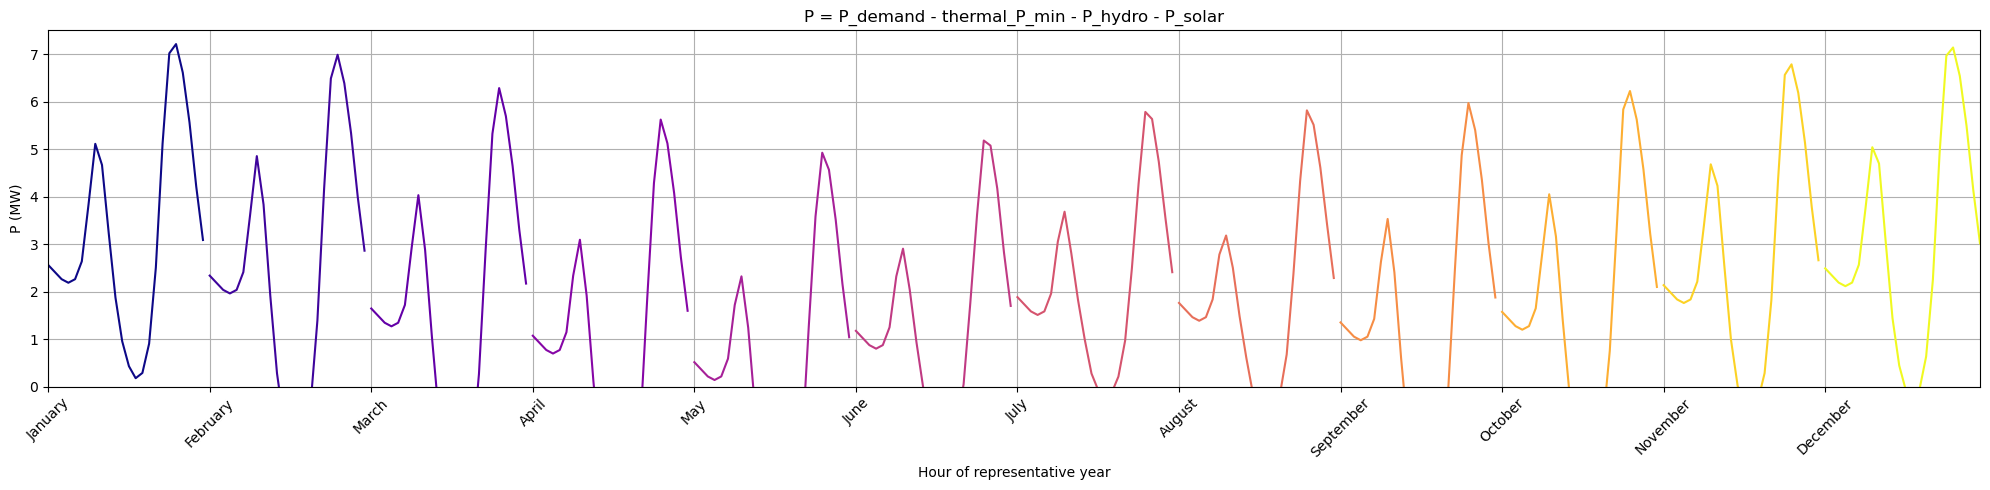

In [39]:
df_solar = pd.read_csv("solar_288h_representative_matrix.csv")
solar_MWp = 8

df_load["P_demand_just_solar_hydro_minThermal"]=df_load["P_demand_for_wind_solar"] - df_solar["P_AC_per_MWp"]*solar_MWp*1e6

plt.figure(figsize=(20, 5))
for month, group in df_load.groupby("Month"):
    plt.plot( (month - 1) * 24 + group["Hour"], group["P_demand_just_solar_hydro_minThermal"]* 1e-6, color=cmap((month - 1) / 11), label=month_names[month - 1], linewidth=1.5    )

plt.xlabel("Hour of representative year")
plt.ylabel("P (MW)")
plt.title("P = P_demand - thermal_P_min - P_hydro - P_solar")

plt.xticks( np.arange(0, 288, 24), month_names, rotation=45 )
plt.xlim(0, 287)
plt.ylim(bottom=0, top=7.5)
plt.grid(True)
#plt.legend(ncol=2)
plt.tight_layout()
plt.show()


In [ ]:
# for month, group in df_load.groupby("Month"):
#     plt.plot( (month - 1) * 24 + group["Hour"], group["P_demand"] * 1e-6, color=cmap((month - 1) / 11), linewidth=1.5) #, label=month_names[month - 1]
 
# thermal_P_min = P_peak * 30 / 100
# plt.plot(np.arange(0, 288,1), (thermal_P_min+P_hydro) * 1e-6, color="green", linestyle="-", label="Minimum thermal power + Hydro")

# plt.xlabel("Hour of representative year")
# plt.ylabel("Demand (MW)")
# plt.xticks( np.arange(0, 288, 24), month_names, rotation=45)
# plt.xlim(0, 287)
# plt.ylim(bottom=0)
# plt.grid(True)
# plt.tight_layout()
# plt.legend()
# plt.show()

Index(['Month', 'Hour', 'U_hub_ms', 'Wind_pu'], dtype='object')


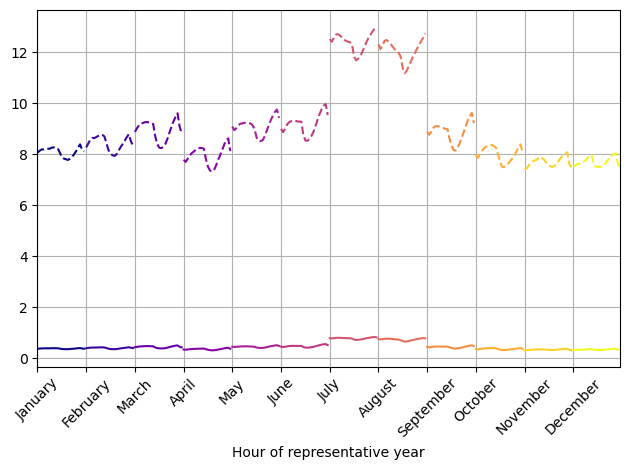

In [49]:
df_wind = pd.read_csv("wind_288_per_MW.csv")
print(df_wind.columns)

for month, group in df_wind.groupby("Month"):
    plt.plot( (month - 1) * 24 + group["Hour"], group["U_hub_ms"], color=cmap((month - 1) / 11), label=month_names[month - 1], linewidth=1.5 , linestyle="--"   )
    plt.plot( (month - 1) * 24 + group["Hour"], group["Wind_pu"], color=cmap((month - 1) / 11), label=month_names[month - 1], linewidth=1.5    )

plt.xlabel("Hour of representative year")
# plt.ylabel("P (MW)")
# plt.title("P = P_demand - thermal_P_min - P_hydro - P_solar")
plt.xticks( np.arange(0, 288, 24), month_names, rotation=45 )
plt.xlim(0, 287)
#plt.ylim(bottom=0, top=7.5)
plt.grid(True)
#plt.legend(ncol=2)
plt.tight_layout()
plt.show()